# Machine translation (German → English): GRU + additive attention vs. transformer encoder-decoder

**Research question.** Attention was invented for machine translation. How does the original recurrent design (a GRU
with additive attention) compare with the transformer, which uses only attention, when both are built from scratch
and trained with the same recipe on the same data? Suggested by Prof. Matthew McNeill.

Sentiment analysis only needed an **encoder**: read the review, output one label. Translation is **sequence-to-sequence**:
read a German sentence, then *generate* an English one word by word. That needs a **decoder** too.

Two models, in the order the field developed them:

1. **GRU encoder-decoder with additive attention**, the setup of Bahdanau, Cho & Bengio (2014), *Neural Machine
   Translation by Jointly Learning to Align and Translate*: the paper that introduced attention, for translation.
2. **Transformer encoder-decoder**, as in Vaswani et al. (2017), *Attention Is All You Need*, which dropped the
   recurrence and used attention everywhere. Built from the same hand-written attention blocks as
   `imdb_baselines_bigru_transformer.ipynb`, plus the new decoder pieces.

Both papers trained on WMT'14 (millions of sentence pairs), far too big for a laptop. **Multi30k** (about 29k short
image-caption pairs, German↔English) is the standard small stand-in, so both models train here in minutes.

| Section | What |
|---|---|
| 1 | Data, checked before modelling |
| 2 | A shared subword vocabulary (SentencePiece BPE) for both languages |
| 3 | Batching |
| 4 | GRU + additive attention encoder-decoder |
| 5 | Transformer encoder-decoder: causal mask, cross-attention |
| 6 | Checks: future tokens can't leak, padding is ignored, step-by-step decoding = training computation, matches `nn.Transformer`, memorises one batch |
| 7 | Training: teacher forcing, label smoothing, warmup schedule (Lightning) |
| 8 | Decoding: greedy and beam search |
| 9 | BLEU, example translations, attention heatmaps |

## 0. Setup

In [1]:
import json
import math
import random
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import sentencepiece as spm
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 0
VOCAB_SIZE = 8_000          # shared German + English BPE vocabulary
BATCH_SIZE = 128            # sentence pairs per batch
EPOCHS = 25
PEAK_LR = 7e-4
WARMUP_STEPS = 800          # about 3.5 epochs
LABEL_SMOOTHING = 0.1
BEAM_SIZE = 5
LENGTH_PENALTY = 0.6        # alpha in ((5 + length) / 6) ** alpha, as in Wu et al. (2016) and Vaswani et al. (2017)

# GRU model
GRU_EMBED_DIM = 256
GRU_HIDDEN_DIM = 256        # per direction in the encoder; the decoder uses 2 x 256 = 512
GRU_ATTN_DIM = 256
GRU_DROPOUT = 0.3

# transformer
MODEL_DIM = 256
NUM_HEADS = 8
FF_DIM = 1024
NUM_LAYERS = 3              # 3 encoder + 3 decoder blocks
TRANSFORMER_DROPOUT = 0.1

device = torch.device("cuda")
print(torch.__version__, "|", torch.cuda.get_device_name(0))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

2.11.0+cu128 | NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Data, checked before modelling

Multi30k: each English image caption has a professional German translation. Standard splits: 29,000 train, 1,014
validation and 1,000 test pairs (the "test2016" set, which most papers report).

In [2]:
DATA_DIR = Path("data/multi30k")
URL = "https://huggingface.co/datasets/bentrevett/multi30k/resolve/main/{split}.jsonl"

def load_split(split):
    path = DATA_DIR / f"{split}.jsonl"
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URL.format(split=split), path)
    rows = [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines()]
    return [r["de"] for r in rows], [r["en"] for r in rows]

data = {split: load_split(file) for split, file in [("train", "train"), ("val", "val"), ("test", "test")]}
for split, (de, en) in data.items():
    print(f"{split:>5}: {len(de):>6} pairs")
de_train, en_train = data["train"]
print("\nexample:\n  de:", de_train[0], "\n  en:", en_train[0])

train:  29000 pairs
  val:   1014 pairs
 test:   1000 pairs

example:
  de: Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche. 
  en: Two young, White males are outside near many bushes.


In [3]:
for split, (de, en) in data.items():
    assert len(de) == len(en)
    empty = [i for i, (d, e) in enumerate(zip(de, en)) if not d.strip() or not e.strip()]
    words_de = np.array([len(d.split()) for d in de])
    words_en = np.array([len(e.split()) for e in en])
    print(f"{split:>5}: empty sentences {len(empty)} | words per sentence, de: median {np.median(words_de):.0f}, "
          f"max {words_de.max()} | en: median {np.median(words_en):.0f}, max {words_en.max()}")
    assert not empty, f"empty sentences in {split}: fix in the data"

train: empty sentences 0 | words per sentence, de: median 11, max 39 | en: median 11, max 37
  val: empty sentences 0 | words per sentence, de: median 11, max 30 | en: median 11, max 27
 test: empty sentences 0 | words per sentence, de: median 10, max 30 | en: median 11, max 32


## 2. A shared subword vocabulary

As with the pretrained models' tokenizers, words are split into subword pieces, so there are no unknown words.
One **SentencePiece BPE** model is trained on the German *and* English training sentences together (not on validation or test):

- German and English share many pieces (names, numbers, "Hund"/"hund", cognates), so one vocabulary of 8,000 pieces covers both.
- With one vocabulary, the transformer can **tie** its source embedding, target embedding and output layer into one
  matrix, as Vaswani et al. did. That cuts parameters and helps on small data.

Special ids: 0 = padding, 1 = unknown, 2 = start of sentence (`<s>`), 3 = end of sentence (`</s>`).

In [4]:
PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
sp_prefix = DATA_DIR / f"bpe{VOCAB_SIZE}"
if not sp_prefix.with_suffix(".model").exists():
    train_text = DATA_DIR / "train_de_en.txt"
    train_text.write_text("\n".join(data["train"][0] + data["train"][1]), encoding="utf-8")
    spm.SentencePieceTrainer.train(input=str(train_text), model_prefix=str(sp_prefix), vocab_size=VOCAB_SIZE,
                                   model_type="bpe", character_coverage=1.0, pad_id=PAD_ID, unk_id=UNK_ID,
                                   bos_id=BOS_ID, eos_id=EOS_ID, minloglevel=2)
sp = spm.SentencePieceProcessor(model_file=str(sp_prefix.with_suffix(".model")))
print("vocabulary size:", sp.get_piece_size())
for sentence in (data["train"][0][0], data["train"][1][0]):
    print(sp.encode(sentence, out_type=str))

encoded = {split: ([sp.encode(s) for s in de], [sp.encode(s) for s in en]) for split, (de, en) in data.items()}
unk_share = sum(ids.count(UNK_ID) for side in encoded["test"] for ids in side) / sum(len(ids) for side in encoded["test"] for ids in side)
print(f"\nunknown pieces in the test set: {unk_share:.3%}")
for split, (de_ids, en_ids) in encoded.items():
    print(f"{split:>5}: pieces per sentence, de: median {np.median([len(i) for i in de_ids]):.0f}, max {max(len(i) for i in de_ids)}"
          f" | en: median {np.median([len(i) for i in en_ids]):.0f}, max {max(len(i) for i in en_ids)}")

vocabulary size: 8000


['▁Zwei', '▁junge', '▁weiße', '▁Männer', '▁sind', '▁im', '▁Freien', '▁in', '▁der', '▁Nähe', '▁viel', 'er', '▁Bü', 'sche', '.']
['▁Two', '▁young', ',', '▁White', '▁males', '▁are', '▁outside', '▁near', '▁many', '▁bushes', '.']



unknown pieces in the test set: 0.000%
train: pieces per sentence, de: median 14, max 52 | en: median 13, max 48
  val: pieces per sentence, de: median 14, max 47 | en: median 14, max 43
 test: pieces per sentence, de: median 13, max 39 | en: median 13, max 33


## 3. Batching

Each example is (German ids, English ids). The English side gets `<s>` at the start and `</s>` at the end. During
training the decoder sees `<s> A man ...` and must predict `A man ... </s>`: the target shifted by one position.
This is **teacher forcing**: at every step the decoder is fed the *correct* previous word, not its own guess, so all
positions can be trained at once.

Length bucketing (`BucketBatchSampler` from `imdb_data.py`) groups sentences of similar source length.

In [5]:
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset

from imdb_data import BucketBatchSampler

class PairDataset(Dataset):
    def __init__(self, src_ids, tgt_ids):
        self.src = [torch.tensor(ids) for ids in src_ids]
        self.tgt = [torch.tensor([BOS_ID] + ids + [EOS_ID]) for ids in tgt_ids]

    def __len__(self):
        return len(self.src)

    def __getitem__(self, index):
        return self.src[index], self.tgt[index]

def collate_pairs(batch):
    src, tgt = zip(*batch)
    src_lengths = torch.tensor([len(s) for s in src])
    return pad_sequence(src, batch_first=True, padding_value=PAD_ID), src_lengths, pad_sequence(tgt, batch_first=True, padding_value=PAD_ID)

datasets = {split: PairDataset(*encoded[split]) for split in encoded}

def make_loader(split, batch_size=BATCH_SIZE):
    is_train = split == "train"
    sampler = BucketBatchSampler([len(s) for s in datasets[split].src], batch_size, shuffle=is_train, drop_last=is_train, seed=SEED)
    return DataLoader(datasets[split], batch_sampler=sampler, collate_fn=collate_pairs)

src, src_lengths, tgt = next(iter(make_loader("train")))
print("src", tuple(src.shape), "| tgt", tuple(tgt.shape))
print("decoder input :", sp.id_to_piece(tgt[0, :8].tolist()))
print("decoder target:", sp.id_to_piece(tgt[0, 1:9].tolist()))

src (128, 14) | tgt (128, 21)
decoder input : ['<s>', '▁A', '▁male', '▁with', '▁sunglasses', '▁is', '▁po', 'king']
decoder target: ['▁A', '▁male', '▁with', '▁sunglasses', '▁is', '▁po', 'king', '▁at']


## 4. GRU encoder-decoder with additive attention (Bahdanau et al., 2014)

- **Encoder:** a bidirectional GRU over the German sentence, as in the BiGRU sentiment model. Each source word gets a
  512-dim state (256 per direction).
- **Decoder:** a GRU that generates English one word at a time. At each step *t*:
  1. **Additive attention** (the same `AdditiveAttention` class as before) compares the decoder's previous state with
     every encoder state and builds a context vector: a weighted average of the source words the decoder is "looking at" now.
  2. The GRU cell reads the previous English word's embedding and the context vector, and updates its state.
  3. A linear layer reads the new state, the context and the previous word, and scores every vocabulary piece for the next word.
- The decoder's first state comes from the encoder's final states (both directions), through a linear layer and tanh.

In the sentiment model attention ran once per review. Here it runs once **per generated word**, so each English word can
look at different German words. That's the "jointly learning to align and translate" of the paper's title.

**One interface for decoding.** Both models expose `start(src, src_lengths)` → decoder state and
`step(state, previous_tokens)` → (log-probabilities of the next token, new state). Greedy and beam search (section 8)
only use these two methods, so they work for both models.

In [6]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

def make_padding_mask(token_ids, lengths):
    positions = torch.arange(token_ids.shape[1], device=token_ids.device)
    return positions.unsqueeze(0) < lengths.to(token_ids.device).unsqueeze(1)   # (batch, seq_len), True = real token


class AdditiveAttention(nn.Module):
    # unchanged from imdb_baselines_bigru_transformer.ipynb
    def __init__(self, decoder_dim, encoder_dim, attn_dim):
        super().__init__()
        self.query_projection = nn.Linear(decoder_dim, attn_dim, bias=False)
        self.key_projection = nn.Linear(encoder_dim, attn_dim, bias=False)
        self.score_projection = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, decoder_states, encoder_states, padding_mask):
        projected_query = self.query_projection(decoder_states)                  # (batch, attn_dim)
        projected_keys = self.key_projection(encoder_states)                     # (batch, seq_len, attn_dim)
        hidden = torch.tanh(projected_query.unsqueeze(1) + projected_keys)       # (batch, seq_len, attn_dim)
        scores = self.score_projection(hidden).squeeze(-1)                       # (batch, seq_len)
        scores = scores.masked_fill(~padding_mask, float("-inf"))
        attention_weights = torch.softmax(scores, dim=1)
        context_vector = (attention_weights.unsqueeze(-1) * encoder_states).sum(dim=1)
        return context_vector, attention_weights


class GRUTranslator(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, attn_dim, dropout):
        super().__init__()
        encoder_dim, decoder_dim = 2 * hidden_dim, 2 * hidden_dim
        self.src_embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.tgt_embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.encoder = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.init_hidden = nn.Linear(encoder_dim, decoder_dim)
        self.attention = AdditiveAttention(decoder_dim, encoder_dim, attn_dim)
        self.decoder_cell = nn.GRUCell(embed_dim + encoder_dim, decoder_dim)
        self.output = nn.Linear(decoder_dim + encoder_dim + embed_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def start(self, src, src_lengths):
        embedded = self.dropout(self.src_embedding(src))
        packed = pack_padded_sequence(embedded, src_lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_states, last_hidden = self.encoder(packed)
        encoder_states, _ = pad_packed_sequence(packed_states, batch_first=True, total_length=src.shape[1])
        hidden = torch.tanh(self.init_hidden(torch.cat(list(last_hidden), dim=-1)))
        return encoder_states, make_padding_mask(src, src_lengths), hidden

    def step(self, state, previous_tokens, return_attention=False):
        encoder_states, padding_mask, hidden = state
        embedded = self.dropout(self.tgt_embedding(previous_tokens))             # (batch, embed_dim)
        context, weights = self.attention(hidden, encoder_states, padding_mask)  # (batch, encoder_dim)
        hidden = self.decoder_cell(torch.cat([embedded, context], dim=-1), hidden)
        logits = self.output(self.dropout(torch.cat([hidden, context, embedded], dim=-1)))
        log_probs = F.log_softmax(logits.float(), dim=-1)
        new_state = (encoder_states, padding_mask, hidden)
        return (log_probs, new_state, weights) if return_attention else (log_probs, new_state)

    def forward(self, src, src_lengths, tgt_in, return_attention=False):
        # teacher forcing: feed the correct previous token at every step
        state = self.start(src, src_lengths)
        all_log_probs, all_weights = [], []
        for t in range(tgt_in.shape[1]):
            log_probs, state, weights = self.step(state, tgt_in[:, t], return_attention=True)
            all_log_probs.append(log_probs)
            all_weights.append(weights)
        log_probs = torch.stack(all_log_probs, dim=1)                            # (batch, tgt_len, vocab)
        return (log_probs, torch.stack(all_weights, dim=1)) if return_attention else log_probs

## 5. Transformer encoder-decoder (Vaswani et al., 2017)

The encoder is the one from the sentiment notebook (pre-LayerNorm blocks). The decoder block has **three** sub-layers,
each with a residual connection:

1. **Masked (causal) self-attention** over the English words generated so far. During training the whole target
   sentence is fed in at once (teacher forcing), so without a mask position 3 could simply look at position 4, the word
   it is supposed to predict. The **causal mask** blocks every position from attending to later positions.
2. **Cross-attention**: queries come from the decoder, keys and values from the encoder's output. This is where the
   decoder looks at the German sentence. It plays the same role as additive attention in the GRU model, with
   multi-head dot-product attention instead.
3. The feed-forward MLP, as in the encoder.

`scaled_dot_product_attention` is the hand-written one from the sentiment notebook. Its padding mask is generalised to
any boolean mask that broadcasts to (batch, heads, queries, keys), which covers padding, the causal mask, or both.

Other details from the paper: embeddings are multiplied by √d before adding the sinusoidal positions, and the source
embedding, target embedding and output layer share one weight matrix (possible because the vocabulary is shared).

In [7]:
def scaled_dot_product_attention(query, key, value, mask):
    # query: (batch, heads, q_len, head_dim); key/value: (batch, heads, k_len, head_dim)
    # mask: bool, broadcastable to (batch, heads, q_len, k_len), True = may attend
    scores = query @ key.transpose(-2, -1) / math.sqrt(query.shape[-1])
    scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ value, weights


class MultiHeadAttention(nn.Module):
    # self-attention when kv is x; cross-attention when kv is the encoder output
    def __init__(self, model_dim, num_heads):
        super().__init__()
        self.num_heads, self.head_dim = num_heads, model_dim // num_heads
        self.query_projection = nn.Linear(model_dim, model_dim)
        self.key_value_projection = nn.Linear(model_dim, 2 * model_dim)
        self.output_projection = nn.Linear(model_dim, model_dim)

    def split_heads(self, x):
        batch, length, _ = x.shape
        return x.view(batch, length, self.num_heads, self.head_dim).transpose(1, 2)

    def forward(self, x, kv, mask):
        query = self.split_heads(self.query_projection(x))
        key, value = self.key_value_projection(kv).chunk(2, dim=-1)
        attended, weights = scaled_dot_product_attention(query, self.split_heads(key), self.split_heads(value), mask)
        batch, _, q_len, _ = attended.shape
        return self.output_projection(attended.transpose(1, 2).reshape(batch, q_len, -1)), weights


def feed_forward(model_dim, ff_dim):
    return nn.Sequential(nn.Linear(model_dim, ff_dim), nn.GELU(), nn.Linear(ff_dim, model_dim))


class EncoderBlock(nn.Module):
    def __init__(self, model_dim, num_heads, ff_dim, dropout):
        super().__init__()
        self.self_attention_norm = nn.LayerNorm(model_dim)
        self.self_attention = MultiHeadAttention(model_dim, num_heads)
        self.feed_forward_norm = nn.LayerNorm(model_dim)
        self.feed_forward = feed_forward(model_dim, ff_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, src_mask):
        normed = self.self_attention_norm(x)
        x = x + self.dropout(self.self_attention(normed, normed, src_mask)[0])
        return x + self.dropout(self.feed_forward(self.feed_forward_norm(x)))


class DecoderBlock(nn.Module):
    def __init__(self, model_dim, num_heads, ff_dim, dropout):
        super().__init__()
        self.self_attention_norm = nn.LayerNorm(model_dim)
        self.self_attention = MultiHeadAttention(model_dim, num_heads)
        self.cross_attention_norm = nn.LayerNorm(model_dim)
        self.cross_attention = MultiHeadAttention(model_dim, num_heads)
        self.feed_forward_norm = nn.LayerNorm(model_dim)
        self.feed_forward = feed_forward(model_dim, ff_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, y, memory, tgt_mask, memory_mask):
        normed = self.self_attention_norm(y)
        y = y + self.dropout(self.self_attention(normed, normed, tgt_mask)[0])
        attended, cross_weights = self.cross_attention(self.cross_attention_norm(y), memory, memory_mask)
        y = y + self.dropout(attended)
        return y + self.dropout(self.feed_forward(self.feed_forward_norm(y))), cross_weights


def sinusoidal_positions(max_len, model_dim):
    positions = torch.arange(max_len).unsqueeze(1)
    frequencies = torch.exp(torch.arange(0, model_dim, 2) * (-math.log(10_000.0) / model_dim))
    encoding = torch.zeros(max_len, model_dim)
    encoding[:, 0::2] = torch.sin(positions * frequencies)
    encoding[:, 1::2] = torch.cos(positions * frequencies)
    return encoding


def causal_mask(length, device):
    return torch.ones(length, length, dtype=torch.bool, device=device).tril()   # position i may attend to 0..i


class TransformerTranslator(nn.Module):
    def __init__(self, vocab_size, model_dim, num_heads, ff_dim, num_layers, dropout, max_len=256):
        super().__init__()
        self.model_dim = model_dim
        self.embedding = nn.Embedding(vocab_size, model_dim, padding_idx=PAD_ID)   # shared: source, target, output
        nn.init.normal_(self.embedding.weight, std=model_dim ** -0.5)
        self.register_buffer("positions", sinusoidal_positions(max_len, model_dim))
        self.encoder_blocks = nn.ModuleList(EncoderBlock(model_dim, num_heads, ff_dim, dropout) for _ in range(num_layers))
        self.decoder_blocks = nn.ModuleList(DecoderBlock(model_dim, num_heads, ff_dim, dropout) for _ in range(num_layers))
        self.encoder_norm = nn.LayerNorm(model_dim)   # pre-LayerNorm stacks need a final norm
        self.decoder_norm = nn.LayerNorm(model_dim)
        self.dropout = nn.Dropout(dropout)

    def embed(self, tokens):
        return self.dropout(self.embedding(tokens) * math.sqrt(self.model_dim) + self.positions[:tokens.shape[1]])

    def encode(self, src, src_lengths):
        src_mask = make_padding_mask(src, src_lengths)[:, None, None, :]        # (batch, 1, 1, src_len)
        x = self.embed(src)
        for block in self.encoder_blocks:
            x = block(x, src_mask)
        return self.encoder_norm(x), src_mask

    def decode(self, tgt_in, memory, src_mask):
        tgt_mask = causal_mask(tgt_in.shape[1], tgt_in.device)[None, None]       # (1, 1, tgt_len, tgt_len)
        y = self.embed(tgt_in)
        cross_weights = []
        for block in self.decoder_blocks:
            y, weights = block(y, memory, tgt_mask, src_mask)
            cross_weights.append(weights)
        logits = self.decoder_norm(y) @ self.embedding.weight.T                  # tied output layer
        return F.log_softmax(logits.float(), dim=-1), cross_weights

    def forward(self, src, src_lengths, tgt_in, return_attention=False):
        memory, src_mask = self.encode(src, src_lengths)
        log_probs, cross_weights = self.decode(tgt_in, memory, src_mask)
        return (log_probs, cross_weights) if return_attention else log_probs

    # decoding interface: the state holds the encoder output and the target prefix so far.
    # Each step re-runs the decoder on the whole prefix (no key/value cache: simpler, and fast enough here).
    def start(self, src, src_lengths):
        memory, src_mask = self.encode(src, src_lengths)
        return memory, src_mask, src.new_zeros(src.shape[0], 0)

    def step(self, state, previous_tokens):
        memory, src_mask, prefix = state
        prefix = torch.cat([prefix, previous_tokens[:, None]], dim=1)
        log_probs, _ = self.decode(prefix, memory, src_mask)
        return log_probs[:, -1], (memory, src_mask, prefix)


make_gru = lambda: GRUTranslator(VOCAB_SIZE, GRU_EMBED_DIM, GRU_HIDDEN_DIM, GRU_ATTN_DIM, GRU_DROPOUT)
make_transformer = lambda: TransformerTranslator(VOCAB_SIZE, MODEL_DIM, NUM_HEADS, FF_DIM, NUM_LAYERS, TRANSFORMER_DROPOUT)
for name, make in [("GRU + attention", make_gru), ("transformer", make_transformer)]:
    print(f"{name:>16}: {sum(p.numel() for p in make().parameters()) / 1e6:.1f}M parameters")

 GRU + attention: 17.6M parameters
     transformer: 7.6M parameters


## 6. Checks before training

1. **The future can't leak.** Changing target tokens at positions ≥ 5 must not change the transformer's outputs at positions < 5.
2. **Padding is ignored.** Appending padding to a source sentence must not change either model's output.
3. **Step-by-step decoding computes the same thing as training.** Generating one token at a time with `step()` must give
   the same log-probabilities as the teacher-forced forward pass, for both models. Otherwise the model would be trained
   on one computation and decoded with another.
4. **The hand-written transformer matches `torch.nn.Transformer`** when given the same weights.
5. **Each model can memorise one batch** (section 7, after the training code).

In [8]:
set_seed(SEED)
src, src_lengths, tgt = [t.to(device) for t in collate_pairs([datasets["val"][i] for i in range(8)])]   # first 8 validation pairs
tgt_in = tgt[:, :-1]
gru, transformer = make_gru().to(device).eval(), make_transformer().to(device).eval()

with torch.no_grad():
    # 1. causal mask
    changed = tgt_in.clone()
    changed[:, 5:] = torch.randint(4, VOCAB_SIZE, changed[:, 5:].shape, device=device)
    assert torch.allclose(transformer(src, src_lengths, tgt_in)[:, :5], transformer(src, src_lengths, changed)[:, :5], atol=1e-5)
    print("1. changing future target tokens leaves earlier outputs unchanged")

    # 2. source padding
    padded_src = torch.cat([src, torch.full((src.shape[0], 7), PAD_ID, device=device)], dim=1)
    for name, model in [("GRU", gru), ("transformer", transformer)]:
        assert torch.allclose(model(src, src_lengths, tgt_in), model(padded_src, src_lengths, tgt_in), atol=1e-5)
    print("2. extra source padding changes nothing, for both models")

    # 3. step-by-step decoding = teacher-forced forward pass
    for name, model in [("GRU", gru), ("transformer", transformer)]:
        full = model(src, src_lengths, tgt_in)
        state = model.start(src, src_lengths)
        stepped = []
        for t in range(tgt_in.shape[1]):
            log_probs, state = model.step(state, tgt_in[:, t])
            stepped.append(log_probs)
        assert torch.allclose(full, torch.stack(stepped, dim=1), atol=1e-4), name
    print("3. step-by-step decoding gives the same log-probabilities as the training computation, for both models")

1. changing future target tokens leaves earlier outputs unchanged
2. extra source padding changes nothing, for both models


3. step-by-step decoding gives the same log-probabilities as the training computation, for both models


In [9]:
# 4. compare with torch.nn.Transformer (pre-LayerNorm, GELU, same sizes) after copying our weights into it
reference = nn.Transformer(d_model=MODEL_DIM, nhead=NUM_HEADS, num_encoder_layers=NUM_LAYERS, num_decoder_layers=NUM_LAYERS,
                           dim_feedforward=FF_DIM, dropout=0.0, activation="gelu", batch_first=True, norm_first=True).to(device).eval()

def copy_attention(ours, theirs):
    theirs.in_proj_weight.data = torch.cat([ours.query_projection.weight, ours.key_value_projection.weight]).clone()
    theirs.in_proj_bias.data = torch.cat([ours.query_projection.bias, ours.key_value_projection.bias]).clone()
    theirs.out_proj.load_state_dict(ours.output_projection.state_dict())

def copy_feed_forward(ours, theirs):
    theirs.linear1.load_state_dict(ours.feed_forward[0].state_dict())
    theirs.linear2.load_state_dict(ours.feed_forward[2].state_dict())

for ours, theirs in zip(transformer.encoder_blocks, reference.encoder.layers):
    copy_attention(ours.self_attention, theirs.self_attn)
    copy_feed_forward(ours, theirs)
    theirs.norm1.load_state_dict(ours.self_attention_norm.state_dict())
    theirs.norm2.load_state_dict(ours.feed_forward_norm.state_dict())
for ours, theirs in zip(transformer.decoder_blocks, reference.decoder.layers):
    copy_attention(ours.self_attention, theirs.self_attn)
    copy_attention(ours.cross_attention, theirs.multihead_attn)
    copy_feed_forward(ours, theirs)
    theirs.norm1.load_state_dict(ours.self_attention_norm.state_dict())
    theirs.norm2.load_state_dict(ours.cross_attention_norm.state_dict())
    theirs.norm3.load_state_dict(ours.feed_forward_norm.state_dict())
reference.encoder.norm.load_state_dict(transformer.encoder_norm.state_dict())
reference.decoder.norm.load_state_dict(transformer.decoder_norm.state_dict())

with torch.no_grad():
    memory, src_mask = transformer.encode(src, src_lengths)
    y = transformer.embed(tgt_in)
    for block in transformer.decoder_blocks:
        y, _ = block(y, memory, causal_mask(tgt_in.shape[1], device)[None, None], src_mask)
    ours_out = transformer.decoder_norm(y)

    src_pad = ~make_padding_mask(src, src_lengths)                              # nn.Transformer: True = padding
    theirs_out = reference(transformer.embed(src), transformer.embed(tgt_in),
                           tgt_mask=~causal_mask(tgt_in.shape[1], device),       # nn.Transformer: True = blocked
                           src_key_padding_mask=src_pad, memory_key_padding_mask=src_pad)
    real = make_padding_mask(tgt_in, (tgt_in != PAD_ID).sum(1))                 # compare at real target positions
    difference = (ours_out - theirs_out)[real].abs().max().item()
print(f"4. largest difference from nn.Transformer: {difference:.2e}")
assert difference < 1e-4
del gru, transformer, reference

C:\research\miniconda3\envs\research\Lib\site-packages\torch\nn\modules\transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


4. largest difference from nn.Transformer: 5.95e-05


## 7. Training

Both models are trained with the same recipe, written as one `LightningModule`:

- **Teacher forcing** (section 3): the decoder is fed the correct previous word.
- **Label smoothing 0.1** (Vaswani et al.): instead of training towards 100% probability on the correct word, the
  target is 90% on it and the other 10% spread over the vocabulary. Many translations are acceptable ("a man" / "one
  man"), and it stops the model from becoming overconfident.
- **Warmup, then inverse-square-root decay** (Vaswani et al.): the LR rises linearly for 800 steps to 7e-4, then falls as
  1/√step. Transformers are unstable early on with a large LR; warmup lets the attention weights settle first.
- Adam with β₂ = 0.98, gradient clipping at 1.0, bf16 mixed precision.
- 25 epochs; the epoch with the **lowest validation loss** is kept.

Padding positions are excluded from the loss (`ignore_index`).

In [10]:
import lightning as L
from lightning.pytorch.callbacks import ModelCheckpoint

def inverse_sqrt_schedule(step):
    step = max(step, 1)
    return min(step / WARMUP_STEPS, math.sqrt(WARMUP_STEPS / step))

class Translator(L.LightningModule):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def loss(self, batch):
        src, src_lengths, tgt = batch
        log_probs = self.model(src, src_lengths, tgt[:, :-1])
        return F.nll_loss(log_probs.reshape(-1, log_probs.shape[-1]), tgt[:, 1:].reshape(-1), ignore_index=PAD_ID) * (1 - LABEL_SMOOTHING) \
            + LABEL_SMOOTHING * -log_probs.mean(-1)[tgt[:, 1:] != PAD_ID].mean()

    def training_step(self, batch, batch_idx):
        loss = self.loss(batch)
        self.log("train_loss", loss, on_step=False, on_epoch=True, batch_size=batch[0].shape[0])
        return loss

    def validation_step(self, batch, batch_idx):
        self.log("val_loss", self.loss(batch), on_epoch=True, batch_size=batch[0].shape[0])

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=PEAK_LR, betas=(0.9, 0.98), eps=1e-9)
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, inverse_sqrt_schedule)
        return [optimizer], [{"scheduler": scheduler, "interval": "step"}]

W1108 04:17:51.651000 12364 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


The loss above is the label-smoothed cross-entropy written out: 90% weight on the correct token's log-probability and
10% on the average log-probability over the whole vocabulary. (`F.cross_entropy(..., label_smoothing=0.1)` computes the
same thing; it's spelled out here so the formula is visible.) The check below confirms they agree.

**Memorising one batch.** Each model trains on a single batch of 32 pairs for 300 steps with dropout off. The loss
should approach its floor (label smoothing keeps it above 0) and greedy decoding should then reproduce the targets.

In [11]:
set_seed(SEED)
src, src_lengths, tgt = next(iter(make_loader("train", batch_size=32)))
batch = [t.to(device) for t in (src, src_lengths, tgt)]
probe = Translator(make_transformer()).to(device).eval()   # eval: dropout off, so both forward passes are identical
log_probs = probe.model(batch[0], batch[1], batch[2][:, :-1])
reference_loss = F.cross_entropy(log_probs.reshape(-1, VOCAB_SIZE), batch[2][:, 1:].reshape(-1), ignore_index=PAD_ID, label_smoothing=LABEL_SMOOTHING)
assert torch.allclose(probe.loss(batch), reference_loss, atol=1e-4)
print("label-smoothed loss matches F.cross_entropy(label_smoothing=0.1)")

def greedy_decode(model, src, src_lengths, max_len):
    state = model.start(src, src_lengths)
    tokens = torch.full((src.shape[0],), BOS_ID, device=src.device)
    finished = torch.zeros_like(tokens, dtype=torch.bool)
    output = []
    for _ in range(max_len):
        log_probs, state = model.step(state, tokens)
        tokens = log_probs.argmax(-1).masked_fill(finished, PAD_ID)
        output.append(tokens)
        finished |= tokens == EOS_ID
        if finished.all():
            break
    output = torch.stack(output, dim=1).tolist()
    return [ids[:ids.index(EOS_ID)] if EOS_ID in ids else ids for ids in output]

for name, make in [("GRU", make_gru), ("transformer", make_transformer)]:
    set_seed(SEED)
    model = make().to(device)
    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.p = 0.0
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    tiny = Translator(model)
    for step in range(300):
        loss = tiny.loss(batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        decoded = greedy_decode(model, batch[0], batch[1], max_len=batch[2].shape[1])
    targets = [[t for t in row[1:] if t not in (PAD_ID, EOS_ID)] for row in batch[2].tolist()]
    exact = np.mean([d == t for d, t in zip(decoded, targets)])
    print(f"{name:>12}: loss after 300 steps {loss.item():.3f} | greedy output identical to target for {exact:.0%} of the 32 sentences")
    assert exact > 0.9, f"{name} could not memorise one batch"
del probe, model, tiny, optimizer
torch.cuda.empty_cache()

label-smoothed loss matches F.cross_entropy(label_smoothing=0.1)


         GRU: loss after 300 steps 1.228 | greedy output identical to target for 100% of the 32 sentences


 transformer: loss after 300 steps 1.234 | greedy output identical to target for 100% of the 32 sentences


### Training both models

Results are saved to `results/translation/<model>.json` and the kept weights to `checkpoints/`, so a finished model is
loaded instead of retrained if the notebook is re-run.

In [12]:
class EpochHistory(L.Callback):
    def on_train_start(self, trainer, module):
        self.rows, self.epoch_start = [], time.time()
    def on_train_epoch_end(self, trainer, module):
        m = trainer.callback_metrics
        self.rows.append({"epoch": trainer.current_epoch + 1, "train_loss": m["train_loss"].item(),
                          "val_loss": m["val_loss"].item(), "seconds": time.time() - self.epoch_start})
        self.epoch_start = time.time()

RESULTS_DIR, CHECKPOINT_DIR = Path("results/translation"), Path("checkpoints")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def train(name, make):
    checkpoint_path = CHECKPOINT_DIR / f"translation_{name}.ckpt"
    saved = RESULTS_DIR / f"{name}.json"
    module = Translator(make())
    if saved.exists():
        module.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=False)["state_dict"])
        result = json.loads(saved.read_text())
        print(f"{name}: loaded saved result (kept epoch {result['kept_epoch']}, val loss {result['val_loss']:.4f})")
        return module.model.to(device).eval(), result
    set_seed(SEED)
    torch.cuda.reset_peak_memory_stats()
    history = EpochHistory()
    checkpoint = ModelCheckpoint(dirpath=CHECKPOINT_DIR, filename=f"translation_{name}", monitor="val_loss", mode="min",
                                 save_top_k=1, save_weights_only=True, enable_version_counter=False)
    trainer = L.Trainer(max_epochs=EPOCHS, precision="bf16-mixed", gradient_clip_val=1.0, callbacks=[history, checkpoint],
                        logger=False, enable_model_summary=False, enable_progress_bar=False, num_sanity_val_steps=0)
    start = time.time()
    trainer.fit(module, make_loader("train"), make_loader("val"))
    module.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=False)["state_dict"])
    best = min(history.rows, key=lambda r: r["val_loss"])
    result = {"model": name, "kept_epoch": best["epoch"], "val_loss": best["val_loss"],
              "train_min": (time.time() - start) / 60, "peak_gb": torch.cuda.max_memory_allocated() / 2**30,
              "parameters_M": sum(p.numel() for p in module.parameters()) / 1e6, "history": history.rows}
    saved.write_text(json.dumps(result, indent=1))
    for row in history.rows:
        print(f"[{name}] epoch {row['epoch']:>2}: train loss {row['train_loss']:.3f} | val loss {row['val_loss']:.3f} | {row['seconds']:.0f}s")
    print(f"[{name}] kept epoch {best['epoch']} (val loss {best['val_loss']:.4f}) | {result['train_min']:.1f} min | peak {result['peak_gb']:.2f} GB")
    return module.model.to(device).eval(), result

models, train_results = {}, {}
for name, make in [("gru_attention", make_gru), ("transformer", make_transformer)]:
    models[name], train_results[name] = train(name, make)

Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA GeForce RTX 4050 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


C:\research\miniconda3\envs\research\Lib\site-packages\lightning\pytorch\callbacks\model_checkpoint.py:881: Checkpoint directory C:\research\research-progress\notebooks\checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (6 outputs left out)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[gru_attention] epoch  1: train loss 6.836 | val loss 5.199 | 23s
[gru_attention] epoch  2: train loss 4.859 | val loss 4.364 | 22s
[gru_attention] epoch  3: train loss 4.132 | val loss 3.774 | 23s
[gru_attention] epoch  4: train loss 3.629 | val loss 3.380 | 23s
[gru_attention] epoch  5: train loss 3.286 | val loss 3.169 | 22s
[gru_attention] epoch  6: train loss 3.077 | val loss 3.070 | 22s
[gru_attention] epoch  7: train loss 2.930 | val loss 2.985 | 23s
[gru_attention] epoch  8: train loss 2.819 | val loss 2.929 | 22s
[gru_attention] epoch  9: train loss 2.731 | val loss 2.896 | 22s
[gru_attention] epoch 10: train loss 2.659 | val loss 2.869 | 22s
[gru_attention] epoch 11: train loss 2.598 | val loss 2.844 | 22s
[gru_attention] epoch 12: train loss 2.546 | val loss 2.830 | 22s
[gru_attention] epoch 13: train loss 2.497 | val loss 2.811 | 22s
[gru_attention] epoch 14: train loss 2.456 | val loss 2.807 | 22s
[gru_attention] epoch 15: train loss 2.420 | val loss 2.795 | 22s
[gru_atten

`Trainer.fit` stopped: `max_epochs=25` reached.


[transformer] epoch  1: train loss 7.201 | val loss 5.189 | 9s
[transformer] epoch  2: train loss 4.676 | val loss 4.085 | 9s
[transformer] epoch  3: train loss 3.864 | val loss 3.491 | 10s
[transformer] epoch  4: train loss 3.363 | val loss 3.144 | 9s
[transformer] epoch  5: train loss 3.008 | val loss 2.949 | 9s
[transformer] epoch  6: train loss 2.776 | val loss 2.848 | 9s
[transformer] epoch  7: train loss 2.613 | val loss 2.771 | 9s
[transformer] epoch  8: train loss 2.486 | val loss 2.740 | 9s
[transformer] epoch  9: train loss 2.374 | val loss 2.707 | 9s
[transformer] epoch 10: train loss 2.282 | val loss 2.701 | 9s
[transformer] epoch 11: train loss 2.205 | val loss 2.699 | 9s
[transformer] epoch 12: train loss 2.135 | val loss 2.698 | 9s
[transformer] epoch 13: train loss 2.073 | val loss 2.713 | 9s
[transformer] epoch 14: train loss 2.018 | val loss 2.725 | 9s
[transformer] epoch 15: train loss 1.968 | val loss 2.733 | 10s
[transformer] epoch 16: train loss 1.924 | val loss 2

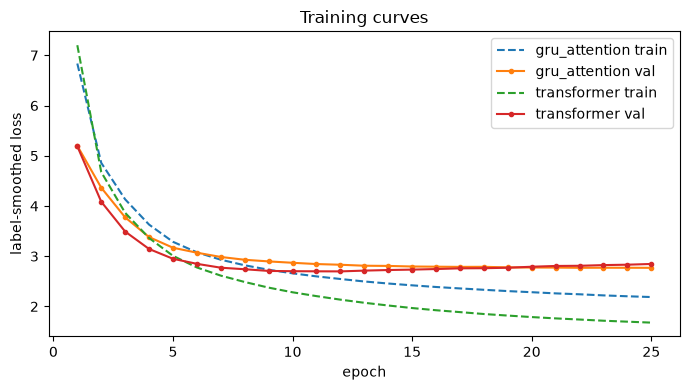

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, r in train_results.items():
    epochs = [row["epoch"] for row in r["history"]]
    ax.plot(epochs, [row["train_loss"] for row in r["history"]], linestyle="--", label=f"{name} train")
    ax.plot(epochs, [row["val_loss"] for row in r["history"]], marker=".", label=f"{name} val")
ax.set(xlabel="epoch", ylabel="label-smoothed loss", title="Training curves")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Decoding: greedy and beam search

Training never generates anything: it scores the correct sentence. To translate, the model must **generate**, feeding
its own previous output back in.

- **Greedy:** at every step, take the single most likely next piece. Fast, but one early mistake can't be undone.
- **Beam search** (beam 5): keep the 5 most likely partial translations at every step, extend each by every possible
  next piece, keep the best 5 of those, and so on. A hypothesis is finished when it produces `</s>`.
  Log-probabilities only go down as a sentence gets longer, so raw scores favour short translations. The final choice
  divides by a **length penalty** `((5 + length) / 6) ** 0.6`, as in the transformer paper.

Generation stops at `</s>` or at `2 × source length + 10` pieces.

In [14]:
def reorder(state, indices):
    return tuple(part[indices] for part in state)

def beam_search(model, src, src_length, beam_size=BEAM_SIZE, alpha=LENGTH_PENALTY):
    # one sentence at a time: src (1, src_len)
    max_len = 2 * src_length.item() + 10
    state = model.start(src, src_length)
    sequences, scores = [[]], torch.zeros(1, device=src.device)
    finished = []
    for _ in range(max_len):
        previous = torch.tensor([seq[-1] if seq else BOS_ID for seq in sequences], device=src.device)
        log_probs, state = model.step(state, previous)                          # (beams, vocab)
        candidates = (scores[:, None] + log_probs).flatten()
        top_scores, top_indices = candidates.topk(2 * beam_size)
        new_sequences, new_scores, keep = [], [], []
        for score, index in zip(top_scores.tolist(), top_indices.tolist()):
            beam, token = divmod(index, log_probs.shape[1])
            if token == EOS_ID:
                finished.append((sequences[beam], score))
            else:
                new_sequences.append(sequences[beam] + [token])
                new_scores.append(score)
                keep.append(beam)
            if len(new_sequences) == beam_size:
                break
        if len(finished) >= beam_size:
            break
        sequences, scores = new_sequences, torch.tensor(new_scores, device=src.device)
        state = reorder(state, torch.tensor(keep, device=src.device))
    if not finished:
        finished = list(zip(sequences, scores.tolist()))
    penalty = lambda length: ((5 + length) / 6) ** alpha
    return max(finished, key=lambda hyp: hyp[1] / penalty(len(hyp[0]) + 1))[0]

@torch.no_grad()
def translate(model, split, method):
    model.eval()
    dataset = datasets[split]
    outputs = []
    if method == "greedy":
        for src, src_lengths, _ in make_loader(split, batch_size=256):
            outputs += greedy_decode(model, src.to(device), src_lengths.to(device), max_len=2 * src.shape[1] + 10)
        # the unshuffled bucketed loader sorts by length: put the outputs back in dataset order
        order = sorted(range(len(dataset)), key=lambda i: len(dataset.src[i]))
        restored = [None] * len(dataset)
        for position, index in enumerate(order):
            restored[index] = outputs[position]
        outputs = restored
    else:
        for src in dataset.src:
            outputs.append(beam_search(model, src[None].to(device), torch.tensor([len(src)], device=device)))
    return [sp.decode(ids) for ids in outputs]

sample = translate(models["transformer"], "val", "greedy")[:3]
for i, hyp in enumerate(sample):
    print(f"de : {data['val'][0][i]}\nref: {data['val'][1][i]}\nhyp: {hyp}\n")

de : Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen
ref: A group of men are loading cotton onto a truck
hyp: A group of men loading tree branches on a truck.

de : Ein Mann schläft in einem grünen Raum auf einem Sofa.
ref: A man sleeping in a green room on a couch.
hyp: A man sleeps on a couch in a green room.

de : Ein Junge mit Kopfhörern sitzt auf den Schultern einer Frau.
ref: A boy wearing headphones sits on a woman's shoulders.
hyp: A young boy wearing headphones sits on a shoulders.



## 9. Evaluation: BLEU

**BLEU** compares a translation with a human reference by counting overlapping word sequences (1 to 4 words long),
with a penalty for translations that are too short. It's computed over the whole test set, from 0 to 100. On
Multi30k, BLEU in the mid-30s is typical for small models. It's an imperfect measure (a correct paraphrase scores low),
which is why example translations follow.

`sacrebleu` computes BLEU on detokenized text with a standard tokenization, so the numbers are comparable with papers.

In [15]:
bleu_results = []
translations = {}
for name, model in models.items():
    for method in ("greedy", "beam"):
        start = time.time()
        hyps = translate(model, "test", method)
        translations[(name, method)] = hyps
        bleu = sacrebleu.corpus_bleu(hyps, [data["test"][1]])
        bleu_results.append({"model": name, "decoding": method, "test BLEU": round(bleu.score, 2),
                             "decode seconds": round(time.time() - start, 1)})
        print(f"{name:>14} {method:>6}: BLEU {bleu.score:5.2f} | {bleu}")
bleu_table = pd.DataFrame(bleu_results)
(RESULTS_DIR / "bleu.json").write_text(bleu_table.to_json(orient="records", indent=1))
bleu_table

 gru_attention greedy: BLEU 36.57 | BLEU = 36.57 68.3/44.1/29.5/20.1 (BP = 1.000 ratio = 1.011 hyp_len = 13097 ref_len = 12955)


 gru_attention   beam: BLEU 37.42 | BLEU = 37.42 70.6/46.2/31.1/21.2 (BP = 0.978 ratio = 0.978 hyp_len = 12668 ref_len = 12955)


   transformer greedy: BLEU 38.11 | BLEU = 38.11 70.0/46.1/31.6/22.1 (BP = 0.984 ratio = 0.984 hyp_len = 12745 ref_len = 12955)


   transformer   beam: BLEU 37.42 | BLEU = 37.42 71.9/47.4/32.2/22.4 (BP = 0.944 ratio = 0.946 hyp_len = 12254 ref_len = 12955)


,model,decoding,test BLEU,decode seconds
0,gru_attention,greedy,36.57,0.6
1,gru_attention,beam,37.42,21.0
2,transformer,greedy,38.11,9.3
3,transformer,beam,37.42,87.9


In [16]:
rng = random.Random(1)
for i in rng.sample(range(len(data["test"][0])), 6):
    print(f"de          : {data['test'][0][i]}")
    print(f"reference   : {data['test'][1][i]}")
    print(f"GRU (beam)  : {translations[('gru_attention', 'beam')][i]}")
    print(f"transformer : {translations[('transformer', 'beam')][i]}\n")

de          : Ein paar Bier-Zapfhähne in einer Bar mit Weihnachtsdekoration an der Decke.
reference   : A bunch of beer pull tabs at a bar with Christmas lights on the ceiling.
GRU (beam)  : A couple of beer are performing in a bar with Christmas lights on the ceiling.
transformer : A bunch of beer and Christmas building with Christmas ceiling in a bar.

de          : Santa Claus wird bei einem Medienevent zu Weihnachten fotografiert.
reference   : Santa Claus being photographed at a holiday media event.
GRU (beam)  : The Claus is being takened in a med race.
transformer : Santa is being played to take a picture at a media.

de          : Eine Frau in einem roten Hemd reitet auf einem weißen Pferd, das an den Bäumen entlang galoppiert.
reference   : A woman in a red shirt is riding an all white horse that is galloping along the trees.
GRU (beam)  : A woman in a red shirt riding a white horse which is trees along the trees.
transformer : A woman in a red shirt is riding a white horse do

### Where the models look: attention heatmaps

For a few test sentences, each model's own (beam) translation is fed back through it with teacher forcing, and the
attention weights are recorded:

- GRU: the additive attention weights at each generated word.
- Transformer: cross-attention in the last decoder layer, averaged over the 8 heads.

Each row is an English piece being generated; each column a German source piece. A good alignment shows up as a rough
diagonal, with jumps where German and English word order differ (German often puts verbs at the end of a clause).

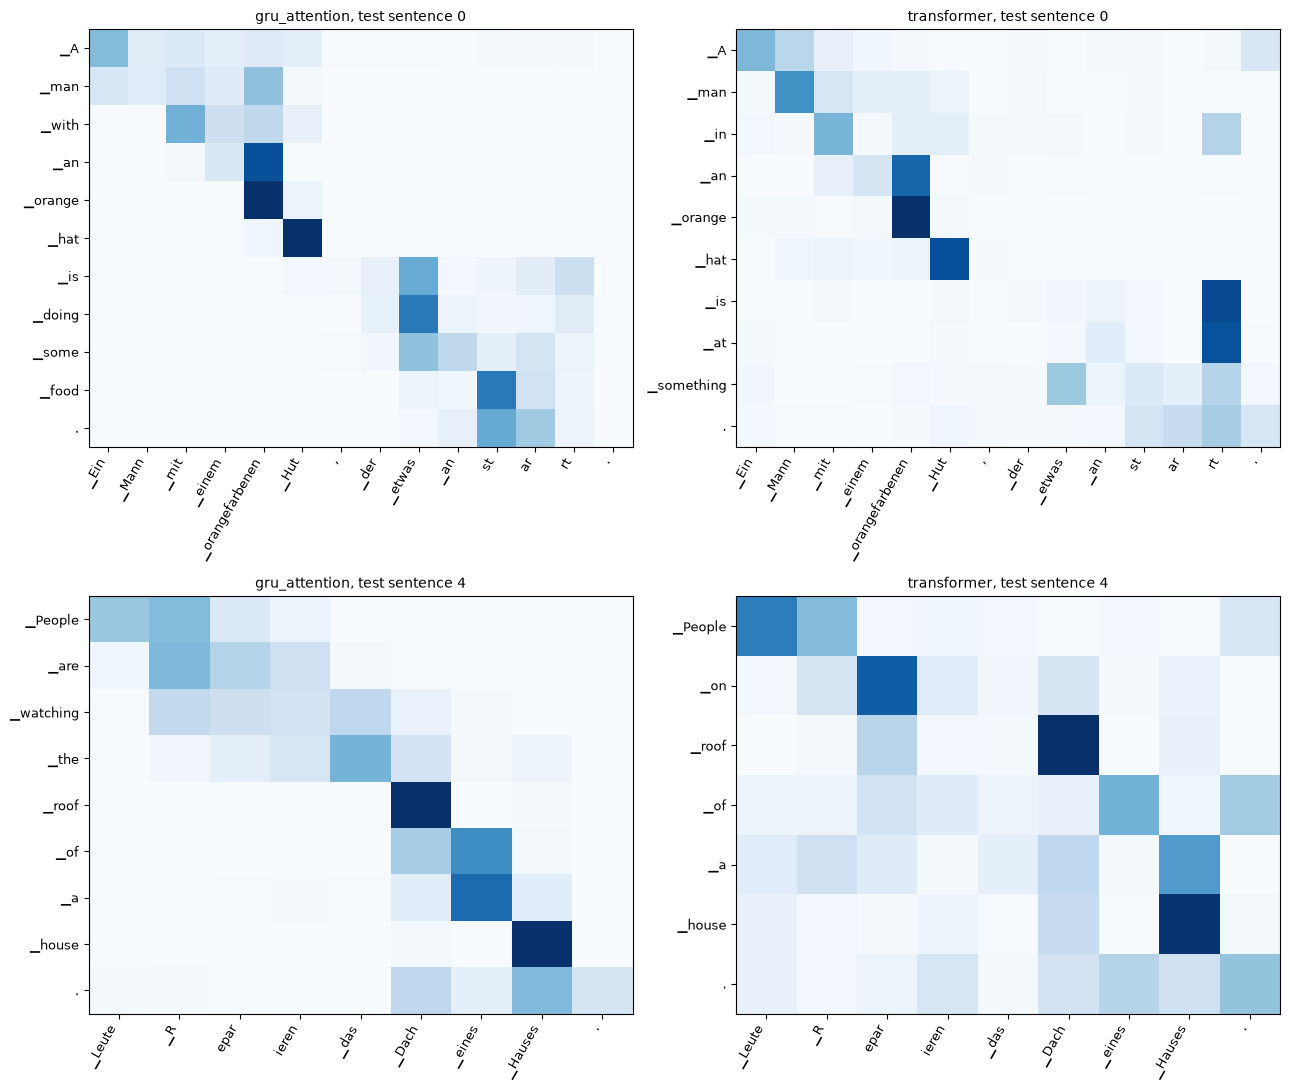

In [17]:
@torch.no_grad()
def attention_map(name, index):
    model = models[name]
    src = datasets["test"].src[index][None].to(device)
    hyp_ids = sp.encode(translations[(name, "beam")][index])
    tgt_in = torch.tensor([[BOS_ID] + hyp_ids], device=device)
    src_lengths = torch.tensor([src.shape[1]], device=device)
    _, weights = model(src, src_lengths, tgt_in, return_attention=True)
    weights = weights[0] if name == "gru_attention" else weights[-1][0].mean(0)   # (tgt_len, src_len)
    return weights.float().cpu().numpy(), sp.id_to_piece(src[0].tolist()), sp.id_to_piece(hyp_ids)

examples = [i for i in range(len(data["test"][0])) if 8 <= len(datasets["test"].src[i]) <= 14][:2]
fig, axes = plt.subplots(len(examples), 2, figsize=(13, 5.5 * len(examples)))
for row, index in enumerate(examples):
    for col, name in enumerate(models):
        weights, src_pieces, tgt_pieces = attention_map(name, index)
        ax = axes[row, col]
        ax.imshow(weights[:len(tgt_pieces)], cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(src_pieces)), src_pieces, rotation=60, ha="right", fontsize=9)
        ax.set_yticks(range(len(tgt_pieces)), tgt_pieces, fontsize=9)
        ax.set_title(f"{name}, test sentence {index}", fontsize=10)
plt.tight_layout()
plt.show()

## 10. Results and what they show

| model | parameters | time per epoch | best val loss (epoch) | test BLEU, greedy | test BLEU, beam 5 |
|---|---|---|---|---|---|
| GRU + additive attention | 17.6M | 22 s | 2.769 (25) | 36.57 | 37.42 |
| transformer, 3+3 layers | 7.6M | 9 s | 2.698 (12) | **38.11** | 37.42 |

**1. The two models translate about equally well.** The best scores differ by 0.7 BLEU. With one training seed and
1,000 test sentences, differences of about 1 BLEU are within the noise, so this run doesn't separate them. Both are in
the range usually reported for small models trained on Multi30k alone.

**2. The transformer gets there with less than half the parameters and in under half the time.** Each epoch takes 9 s
instead of 22 s, because the transformer processes all positions of a sentence at once. The GRU has to step through it
word by word. That parallelism is the transformer paper's main practical argument.

**3. The transformer overfits; the GRU had just stopped improving.** The transformer's validation loss is lowest at
epoch 12 and rises after that, while its training loss keeps falling. Checkpointing by validation loss kept epoch 12.
The GRU's validation loss was still creeping down at epoch 25 (2.774 → 2.769 over the last 5 epochs), so it had
essentially converged. Dropout 0.1 is the transformer paper's value for millions of sentence pairs; with only 29,000,
more dropout would probably help. That's an obvious next experiment.

**4. Beam search helped the GRU (+0.85) but hurt the transformer (−0.69), and the reason is length.** For the
transformer, beam search raised every n-gram precision (1-gram 70.0 → 71.9, 4-gram 22.1 → 22.4), so its words were
*more* accurate. But its translations got shorter: 94.6% of the reference length, against 98.4% with greedy. BLEU's
brevity penalty then cut the score by 5.6%. Beam search picks the highest-probability sentence, and shorter sentences
have higher probability; the length penalty (α = 0.6, from the transformer paper) only partly offsets that. The fix is
to choose α on the **validation** set, not the test set. The paper also tuned α on development data.

**5. Errors come from rare words.** Both models handle common scene descriptions well, often with paraphrases a human
would accept ("sits together on the sidewalk relaxing"). They fail on words that are rare in 29,000 training captions:
*Zapfhähne* (beer taps), *Medienevent*, *anstarrt* (stares at). BPE splits these into fragments (`_an st ar rt`) that
the models never saw used in that combination. Nonsense like "takened in a med race" is the result.

**6. The attention maps show sensible alignments.** Both models attend roughly along the diagonal, with clear
word-to-word matches: *orangefarbenen → orange*, *Hut → hat*, *Dach → roof*, *Hauses → house*. Where the models
mistranslate *anstarrt*, the attention over its four fragments is spread out and unfocused.

**Possible next steps:**
- choose the beam length penalty α on the validation set
- try more dropout for the transformer
- repeat both models with 2–3 seeds, so the BLEU difference can be judged against run-to-run variation